In [1]:
import xarray as xr

rain = xr.open_dataarray("data/processed/imerg_kerala_2020-06-01_2020-09-30.nc")
tdps = xr.open_dataarray("/Users/jazanowrin/Desktop/tdps_jjas2020_kerala.nc")

print(rain.shape, rain.dims)
print(tdps.shape, tdps.dims)
print(rain.lat.values[:3], rain.lon.values[:3])
print(tdps.lat.values[:3], tdps.lon.values[:3])
print(rain.time.values[:2])
print(tdps.time.values[:2])

(122, 70, 70) ('time', 'lon', 'lat')
(122, 25, 25) ('time', 'lat', 'lon')
[7.05 7.15 7.25] [72.05 72.15 72.25]
[7.16627415 7.44730451 7.72833487] [72.      72.28125 72.5625 ]
['2020-06-01T00:00:00.000000000' '2020-06-02T00:00:00.000000000']
['2020-06-01T12:00:00.000000000' '2020-06-02T12:00:00.000000000']


In [2]:
import numpy as np
import xarray as xr

rain = xr.open_dataarray("data/processed/imerg_kerala_2020-06-01_2020-09-30.nc")
tdps = xr.open_dataarray("/Users/jazanowrin/Desktop/tdps_jjas2020_kerala.nc")

# 1. same dimension order
rain = rain.transpose("time", "lat", "lon")

# 2. same time stamps (keep the date, drop 12:00)
tdps["time"] = tdps.time.dt.floor("D")

# 3. edges of the ERA5 cells (halfway between neighbouring centres)
def edges(c):
    mid = (c[1:] + c[:-1]) / 2
    return np.concatenate([[c[0] - (mid[0] - c[0])], mid, [c[-1] + (c[-1] - mid[-1])]])

lat_e = edges(tdps.lat.values)
lon_e = edges(tdps.lon.values)

# 4. average the IMERG cells that fall inside each ERA5 cell
rain_c = (rain.groupby_bins("lat", lat_e, labels=tdps.lat.values).mean()
              .groupby_bins("lon", lon_e, labels=tdps.lon.values).mean())
rain_c = rain_c.rename({"lat_bins": "lat", "lon_bins": "lon"})
rain_c = rain_c.transpose("time", "lat", "lon")

# 5. checks
print(rain_c.shape, tdps.shape)
print("mean rain before/after:", float(rain.mean()), float(rain_c.mean()))
print("dates match:", bool((rain_c.time.values == tdps.time.values).all()))

(122, 25, 25) (122, 25, 25)
mean rain before/after: 10.485455513000488 10.649490356445312
dates match: True


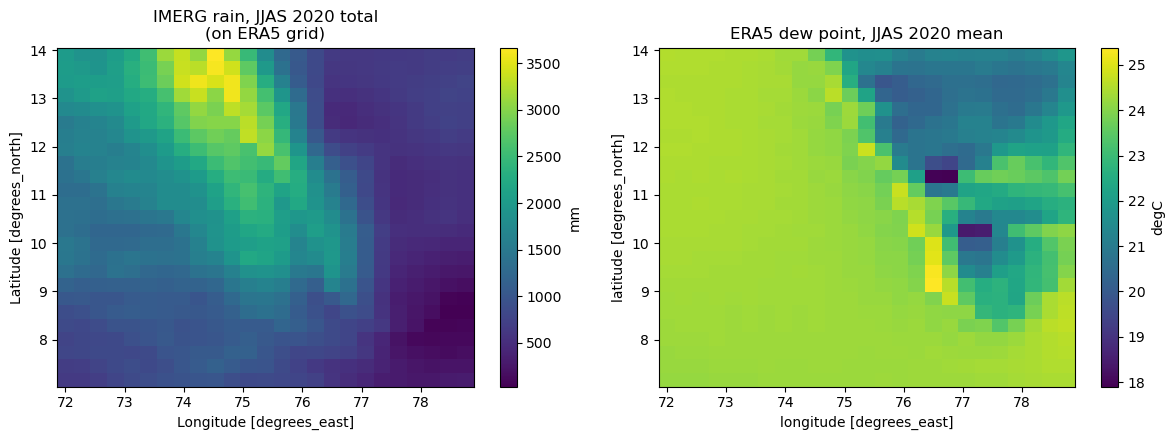

<xarray.Dataset>
Dimensions:  (time: 122, lat: 25, lon: 25)
Coordinates:
  * time     (time) datetime64[ns] 2020-06-01 2020-06-02 ... 2020-09-30
  * lat      (lat) float64 7.166 7.447 7.728 8.009 ... 13.07 13.35 13.63 13.91
  * lon      (lon) float64 72.0 72.28 72.56 72.84 ... 77.91 78.19 78.47 78.75
Data variables:
    rain     (time, lat, lon) float32 0.52 0.18 1.322 ... 11.82 12.18 10.8
    tdps     (time, lat, lon) float32 24.74 24.78 24.85 ... 21.59 22.11 22.47


In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
rain_c.sum("time").plot(ax=ax[0], cbar_kwargs={"label": "mm"})
ax[0].set_title("IMERG rain, JJAS 2020 total\n(on ERA5 grid)")
tdps.mean("time").plot(ax=ax[1], cbar_kwargs={"label": "degC"})
ax[1].set_title("ERA5 dew point, JJAS 2020 mean")
plt.tight_layout()
plt.savefig("harmonised_rain_tdps_jjas2020.png", dpi=200, bbox_inches="tight")
plt.show()

# Save the harmonised dataset
import xarray as xr
ds = xr.Dataset({"rain": rain_c.rename("rain"), "tdps": tdps.rename("tdps")})
ds["rain"].attrs["units"] = "mm/day"
ds["tdps"].attrs["units"] = "degC"
ds.to_netcdf("data/processed/harmonised_rain_tdps_jjas2020.nc")
print(ds)